# IMPORT

In [236]:
import pandas as pd
from pathlib import Path
import os

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt


# FIX FOR THE KMEANS PROBLEM

In [237]:
# To solve the memory leak problem for K-Means in Windows
os.environ["OMP_NUM_THREADS"] = "6"

# DEFINE FOLDERS

In [238]:
STATION_FEATURE_FOLDER = Path("../data/02_features/station_features")
STATION_CLUSTER_FOLDER = Path("../data/03_clustering/station_clusters")
CLUSTER_SUMMARY_FOLDER = Path("../data/03_clustering/cluster_summary")
CLUSTER_PLOT_FOLDER = Path("../data/03_clustering/cluster_plots")

folders = [STATION_FEATURE_FOLDER, STATION_CLUSTER_FOLDER, CLUSTER_SUMMARY_FOLDER, CLUSTER_PLOT_FOLDER]
for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

# DEFINE CONSTANTS

In [239]:
RANDOM_STATE = 72
K = 2 # Should be choosen after seeing the plot etc, but so far only 2 worked well so
ALL_FEATURES = True # If not true, we only use behavioral features(the most correlated 5 features) without the weather features

# LOAD DATA

In [240]:
df = pd.read_csv(f"{STATION_FEATURE_FOLDER}/station_features.csv")

print("Stations:", df.shape[0])

Stations: 1417


# ADD A NEW FEATURE

In [241]:
"""
stationcode,mean_usage,std_usage,min_usage,max_usage,mean_weekend,mean_weekday,day_usage,night_usage,daily_amplitude,
corr_weather_temperature_2m,corr_weather_wind_speed_10m,corr_weather_wind_direction_10m,corr_weather_weather_code,latitude,longitude,capacity
"""

"""
corr_weather_temperature_2m     *  +
corr_weather_wind_speed_10m     *  +
corr_weather_wind_direction_10m *  +
corr_weather_weather_code       * 
"""
# We did not continue on working on a new feature as the weather data does not correlate with stations that much.

'\ncorr_weather_temperature_2m     *  +\ncorr_weather_wind_speed_10m     *  +\ncorr_weather_wind_direction_10m *  +\ncorr_weather_weather_code       * \n'

# SELECT FEATURES FOR CLUSTERING

In [242]:
print(df.columns)

Index(['station_code', 'mean_usage', 'std_usage', 'min_usage', 'max_usage',
       'mean_weekend', 'mean_weekday', 'day_usage', 'night_usage',
       'daily_amplitude', 'corr_temperature', 'corr_wind_speed',
       'corr_wind_direction', 'corr_weather_code', 'latitude', 'longitude',
       'capacity'],
      dtype='object')


In [243]:
"""
to exclude:
-stationcode
-latitude/longitude (for now)
-capacity (size != behavior)
"""
# # means we can remove to improve clustering quality
cluster_features = [
    "mean_usage",
    "mean_weekend",
    "mean_weekday",
    "day_usage",
    "night_usage",
]
# We can remove them because the chosen 5 are the most correlated features.
# It is also visible in the methods below that this makes it easier to cluster.
# But for the sake of the hypothesis and project, we will keep them for now.
if ALL_FEATURES:
    cluster_features = cluster_features + [
        "std_usage", #
        "daily_amplitude", #
        "corr_temperature", #
        "corr_wind_speed", #
        "corr_wind_direction", #
        "corr_weather_code", #
    ]

cluster_features = [c for c in cluster_features if c in df.columns]

X = df[cluster_features]
print("Clustering features:", cluster_features)

Clustering features: ['mean_usage', 'mean_weekend', 'mean_weekday', 'day_usage', 'night_usage', 'std_usage', 'daily_amplitude', 'corr_temperature', 'corr_wind_speed', 'corr_wind_direction', 'corr_weather_code']


# SCALE FEATURES

In [244]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# CHOOSE NUMBER OF CLUSTERS (ELBOW METHOD)

c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning:

2 9748.792422412931
3 8039.408212521776
4 7125.035582561044
5 6526.763354950684
6 6072.334841212976
7 5673.272147684805
8 5381.077505729453
9 5123.78095729497
10 4912.8794525459425


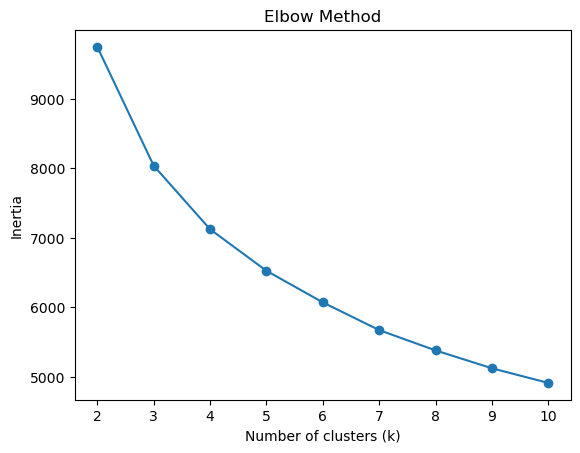

In [245]:
inertias = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

for x, y in zip(K_range, inertias):
    print(x, y)

plt.figure()
plt.plot(K_range, inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

# FOR ALL FEATURES
# Inertia drops quickly at small k, then flattens.
# No clear elbow, gains diminish after k=2–3.
# FOR BEHAVIORAL FEATURES
# Inertia decreases sharply from k=2 (2022) to k=3 (1270), then more slowly.
# No clear elbow, suggesting diminishing returns beyond k=2–3.

# CHOOSE NUMBER OF CLUSTERS (SILHOUETTE SCORE)

In [246]:
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    print(f"k={k} -> silhouette={score:.3f}")

# FOR ALL FEATURES
# Highest score at k=2 (~0.34), indicating moderate cluster separation.
# Scores drop or remain similar for higher k, showing weaker distinction.
# FOR BEHAVIORAL FEATURES
# k=2 -> 0.589 (highest, best-separated clusters)
# k=3 -> 0.484, k=4 -> 0.391, k=5 -> 0.410, k=6 -> 0.352, k=7 -> 0.340
# Adding more clusters reduces separation.

c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


k=2 -> silhouette=0.338
k=3 -> silhouette=0.325


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


k=4 -> silhouette=0.292


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


k=5 -> silhouette=0.300


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


k=6 -> silhouette=0.225


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


k=7 -> silhouette=0.215


# FINAL CLUSTERING

In [247]:
kmeans = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=50)
df["cluster"] = kmeans.fit_predict(X_scaled)

print(df["cluster"].value_counts())


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


cluster
1    724
0    693
Name: count, dtype: int64


# GET FILE TAG

In [248]:
CLUSTER_METHOD = "kmeans"
FEATURE_SET_NAME = "behavior+weather" if ALL_FEATURES else "behavior"
FILE_TAG = f"{CLUSTER_METHOD}_k{K}_feat_{FEATURE_SET_NAME}_rs{RANDOM_STATE}"
# We do this to not have complicated file names and to have a fixed name system

# SAVE STATION-CLUSTER MAPPING

In [249]:
df[["station_code", "cluster"]].to_csv(
    f"{STATION_CLUSTER_FOLDER}/station_clusters_{FILE_TAG}.csv", index=False
)

print(f"Saved {STATION_CLUSTER_FOLDER}/station_clusters_{FILE_TAG}.csv")

Saved ..\data\03_clustering\station_clusters/station_clusters_kmeans_k2_feat_behavior+weather_rs72.csv


# UNDERSTANDING WHAT EACH CLUSTER MEANS

In [250]:
cluster_summary = (
    df.groupby("cluster")[cluster_features]
    .mean()
    .round(3)
)

cluster_summary.to_csv(f"{CLUSTER_SUMMARY_FOLDER}/cluster_summary_{FILE_TAG}.csv")
print(cluster_summary)
print(f"Saved: {CLUSTER_SUMMARY_FOLDER}/cluster_summary_{FILE_TAG}.csv")

         mean_usage  mean_weekend  mean_weekday  day_usage  night_usage  \
cluster                                                                   
0             0.548         0.550         0.548      0.562        0.541   
1             0.247         0.256         0.243      0.216        0.264   

         std_usage  daily_amplitude  corr_temperature  corr_wind_speed  \
cluster                                                                  
0            0.248            0.322            -0.017            0.039   
1            0.181            0.230            -0.058           -0.068   

         corr_wind_direction  corr_weather_code  
cluster                                          
0                      0.020              0.010  
1                     -0.036              0.025  
Saved: ..\data\03_clustering\cluster_summary/cluster_summary_kmeans_k2_feat_behavior+weather_rs72.csv


# VISUAL CHECK

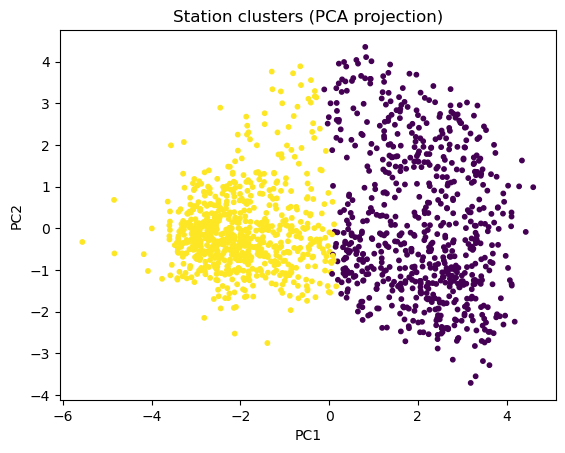

In [251]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure()
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df["cluster"], s=10)
plt.title("Station clusters (PCA projection)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.savefig(f"{CLUSTER_PLOT_FOLDER}/station_clusters_pca_{FILE_TAG}.png", dpi=300, bbox_inches='tight')
plt.show()
